In [36]:
import functools
import numpy as np
import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
from qiskit_experiments.framework import ExperimentData
import qiskit_dynamics as qk_d
import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from scipy.optimize import curve_fit
import qutip as qt
from tqdm import tqdm

import sys

sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

# Full calibration of APL pi pulses on two qubits

In [3]:
from qiskit_ibm_runtime import QiskitRuntimeService, Session, SamplerV2 as Sampler

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
service = QiskitRuntimeService(token=IBM_TOKEN, channel="ibm_quantum")

In [4]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

# backend = qk_fp.FakeManila()
backend = service.get_backend("ibm_nazca")
dt = backend.configuration().dt * ns

# desired_duration = 128 # dt, apl pulses
desired_duration = 120 # dt, new pulses

granularity = backend.configuration().timing_constraints["granularity"]

GATE_TIME_SI_UNITS = desired_duration * dt / ns
duration = ps.qiskit_closest_multiple(GATE_TIME_SI_UNITS, backend, granularity)
dt, granularity, duration

(0.5, 8, 120)

In [5]:
# pico_a = ps.from_csv(
#     "../pico-pulses/apl-pulses/x_gates.csv" # gates with 2 pi offset
# )
pico_a = ps.from_csv(
    "../pico-pulses/saved-pulses-2024-06-27/single_qubit_gateset.csv" # gates without 2 pi offset
)
pico_gates = {key: row for key, row in zip(["x1", "i1", "x2", "i2"], pico_a)}

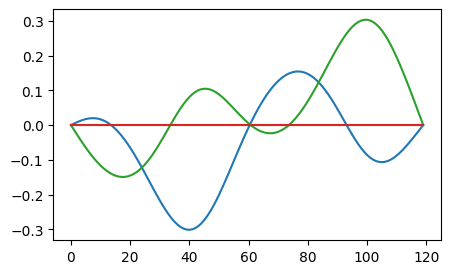

In [6]:
fig, ax = plt.subplots(figsize=[5, 3])
for row in pico_a:
    ax.plot(row)

In [7]:
np.trapz(pico_gates["x1"], dx=dt), np.trapz(pico_gates["x2"], dx=dt)

(-3.1373487889817544, 3.137413414080159)

In [8]:
default_gates = {
    "x1": np.real(ps.gaussian_envelope(duration, dt=dt, angle=np.pi).samples),
    "x2": np.real(ps.gaussian_envelope(duration, dt=dt, angle=np.pi).samples)
}

In [9]:
np.trapz(default_gates["x1"], dx=dt), np.trapz(default_gates["x2"], dx=dt)

(3.141507075143458, 3.141507075143458)

# Qubits to use

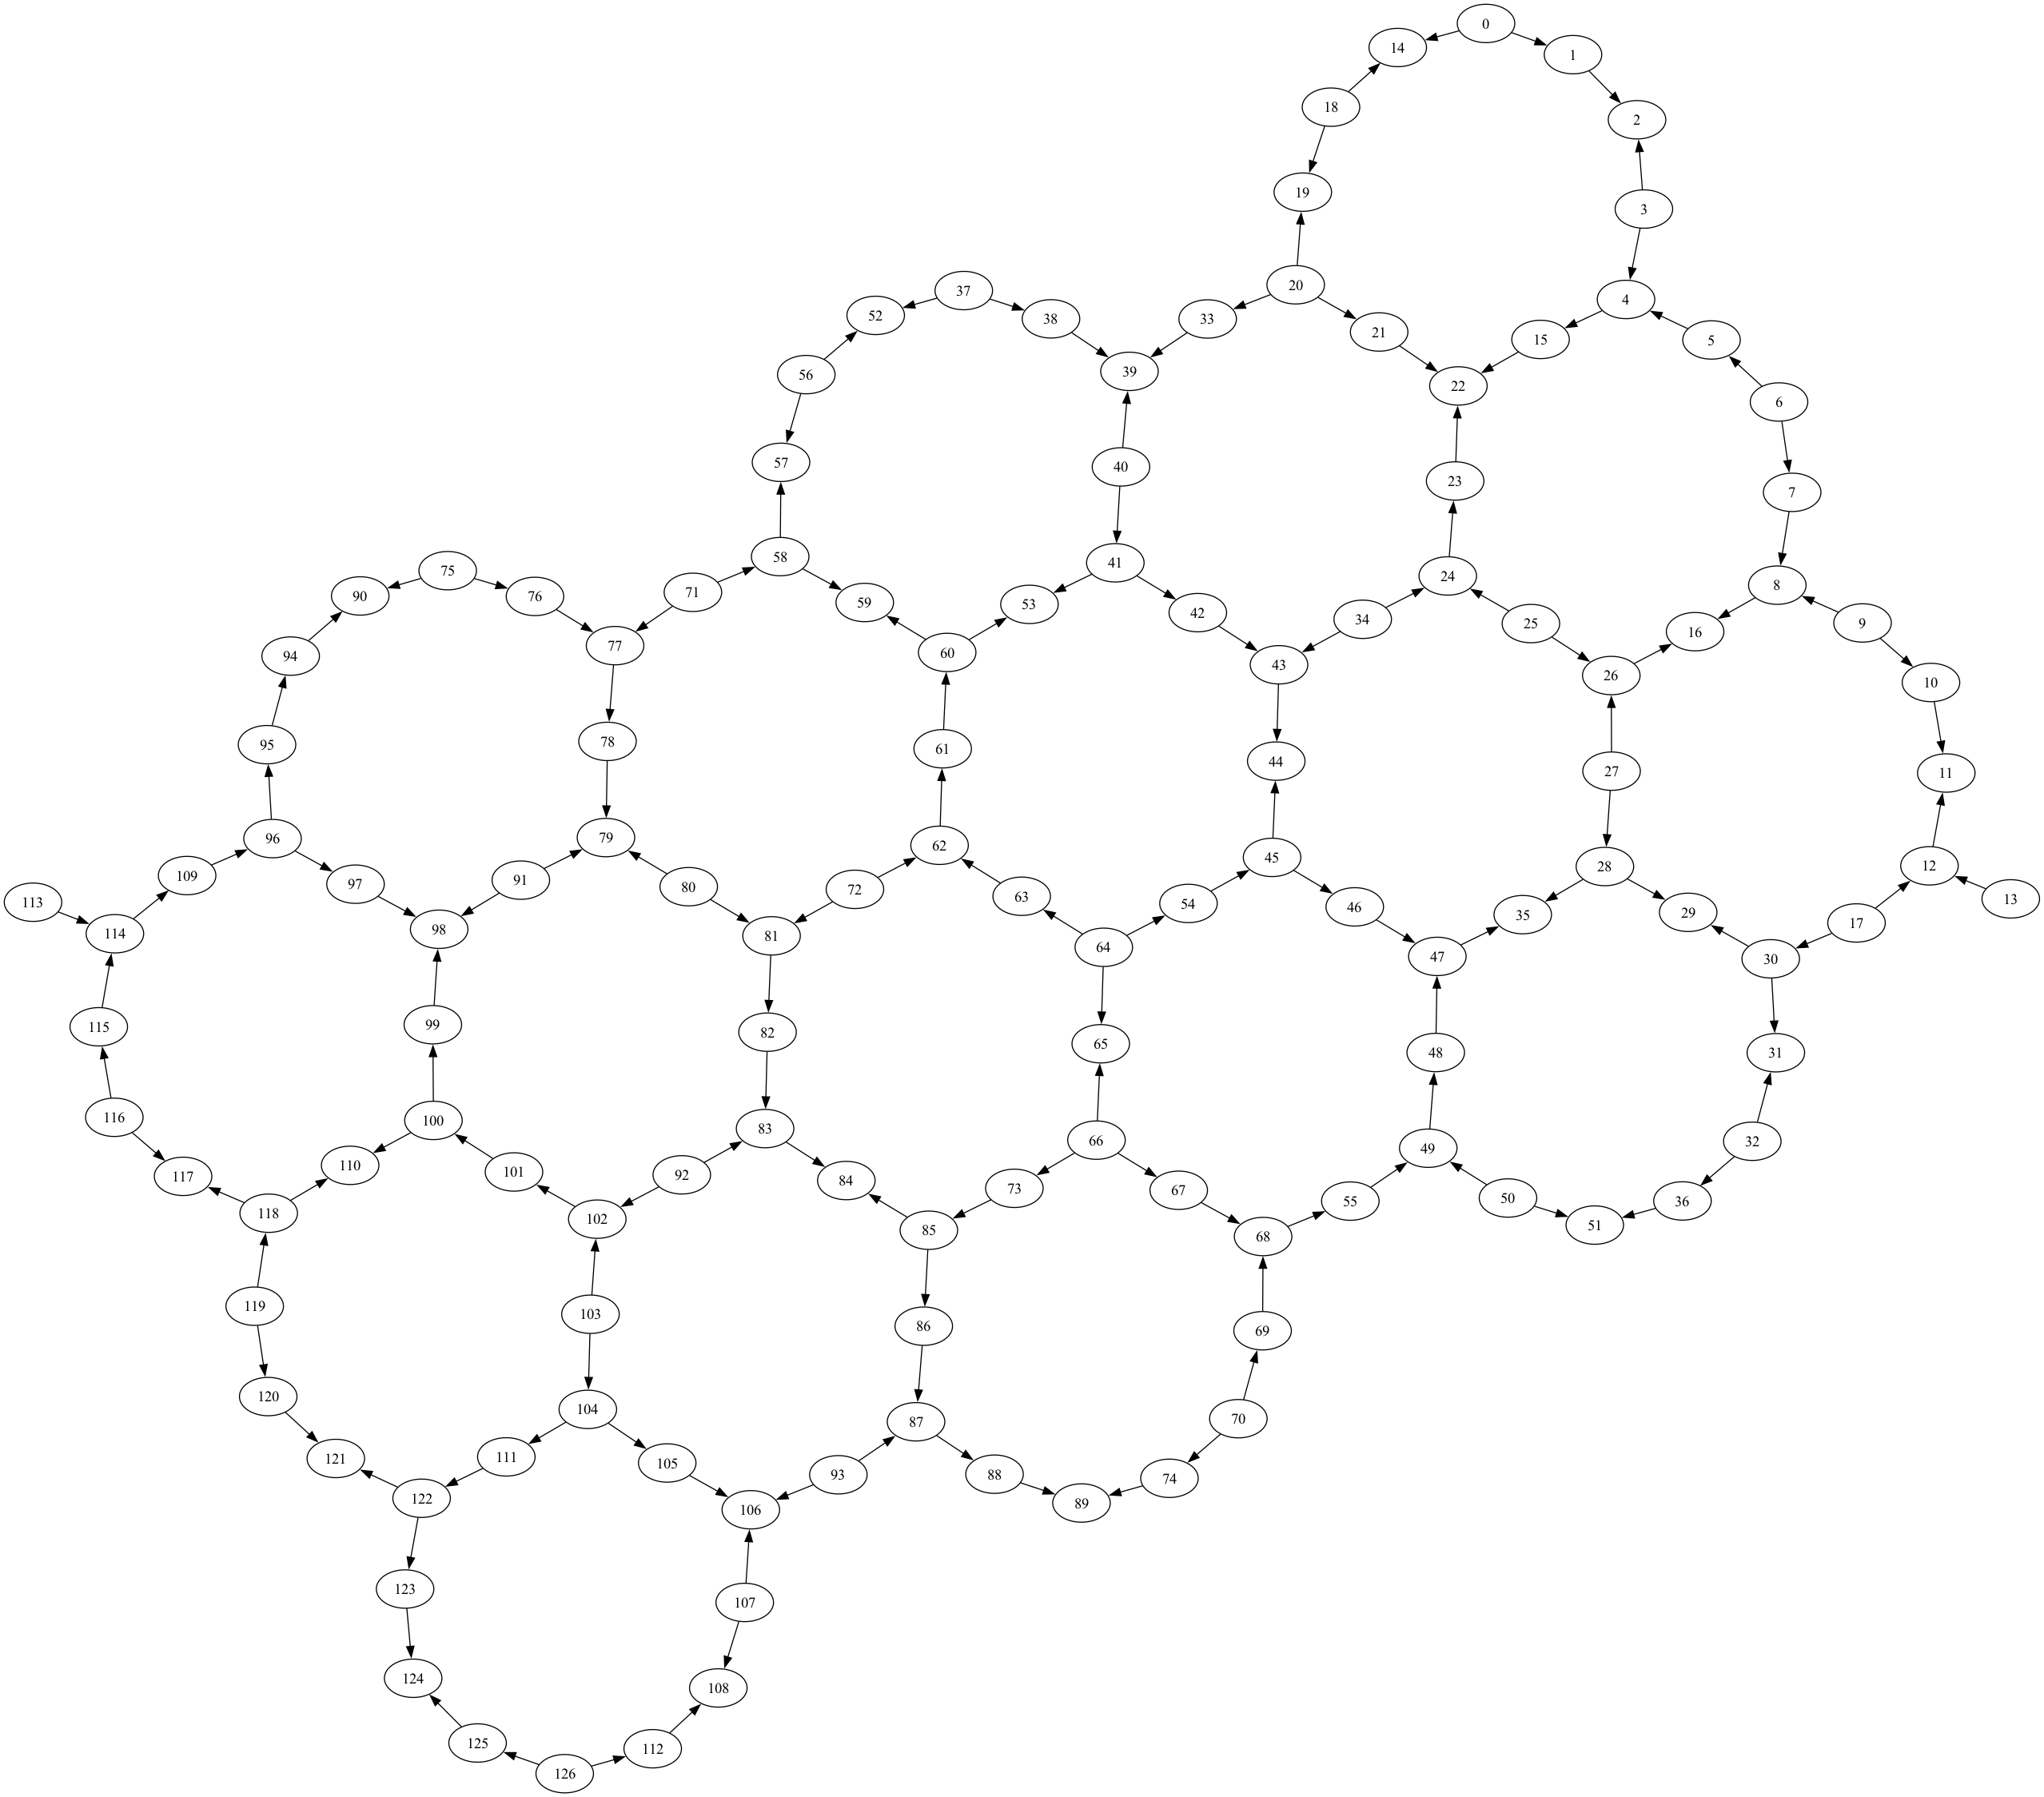

In [10]:
backend.coupling_map.draw()

In [11]:
qubit0 = 4
qubit1 = 3

In [12]:
backend.configuration().hamiltonian['vars']['jq3q4'] * GHz / 2 / np.pi

0.00209104364613846

In [13]:
backend.properties().to_dict()['qubits'][qubit0][0], backend.properties().to_dict()['qubits'][qubit0][1]

({'date': datetime.datetime(2024, 6, 26, 7, 9, 38, tzinfo=tzlocal()),
  'name': 'T1',
  'unit': 'us',
  'value': 316.77866076880474},
 {'date': datetime.datetime(2024, 6, 26, 7, 23, 38, tzinfo=tzlocal()),
  'name': 'T2',
  'unit': 'us',
  'value': 238.04016164531183})

In [14]:
backend.properties().to_dict()['qubits'][qubit1][0], backend.properties().to_dict()['qubits'][qubit1][1]

({'date': datetime.datetime(2024, 6, 26, 7, 9, 38, tzinfo=tzlocal()),
  'name': 'T1',
  'unit': 'us',
  'value': 134.49634062423698},
 {'date': datetime.datetime(2024, 6, 25, 17, 18, 20, tzinfo=tzlocal()),
  'name': 'T2',
  'unit': 'us',
  'value': 202.4320286958388})

In [15]:
backend.status()

## Rough calibration

In [16]:
from qiskit.circuit import Parameter
import qiskit.pulse as pulse
from qiskit_experiments.calibration_management.calibrations import Calibrations
from qiskit_experiments.library.calibration import RoughAmplitudeCal

In [17]:
def add_sched(cals, backend, gate_key, qubit, gates) -> Calibrations:
    amp = Parameter("amp")
    channel = pulse.DriveChannel(qubit)

    with qk.pulse.build(name="x", backend=backend) as x90p:
        signal = gates[gate_key]
        signal_samples = ps.resample(
            duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
        )
        param_gate = ps.scalable_symbolic_pulse(
            duration, signal_samples, "x", amp=amp
        )
        qk.pulse.play(param_gate, channel)
    print(f"Max amplitude: {np.max(np.abs(signal_samples))}")
    cals.add_schedule(x90p, (qubit,))

In [18]:
cals = Calibrations.from_backend(backend)
add_sched(cals, backend, "x1", qubit0, pico_gates)
add_sched(cals, backend, "x2", qubit1, pico_gates)

Max amplitude: 0.3012678011173944
Max amplitude: 0.30303932801317945


In [19]:
gaussian_cals = Calibrations.from_backend(backend)
add_sched(gaussian_cals, backend, "x1", qubit0, default_gates)
add_sched(gaussian_cals, backend, "x2", qubit1, default_gates)

Max amplitude: 0.09699861422442428
Max amplitude: 0.09699861422442428


In [21]:
# set some starting value for amplitude
cals.add_parameter_value(0.5, Parameter("amp"), (qubit0,), "x")
cals.add_parameter_value(0.5, Parameter("amp"), (qubit1,), "x") 

gaussian_cals.add_parameter_value(0.5, Parameter("amp"), (qubit0,), "x")
gaussian_cals.add_parameter_value(0.5, Parameter("amp"), (qubit1,), "x")

In [22]:
drive_amps_1 = np.linspace(-2.5, 2.5, 51)
rabi_x1 = RoughAmplitudeCal(
    physical_qubits=(qubit0,), 
    calibrations=cals, 
    backend=backend, 
    amplitudes=drive_amps_1, 
    target_angle=np.pi, 
)

drive_amps_2 = np.linspace(-2.5, 2.5, 51)
rabi_x2 = RoughAmplitudeCal(
    physical_qubits=(qubit1,), 
    calibrations=cals, 
    backend=backend, 
    amplitudes=drive_amps_2, 
    target_angle=np.pi, # 3 pi if working with offset
)

In [23]:
drive_amps_guass_1 = np.linspace(-5, 5, 51)
rabi_x1_gaussian = RoughAmplitudeCal(
    physical_qubits=(qubit0,), 
    calibrations=gaussian_cals, 
    backend=backend, 
    amplitudes=drive_amps_guass_1, 
    target_angle=np.pi, 
)

drive_amps_guass_2 = np.linspace(-5, 5, 51)
rabi_x2_gaussian = RoughAmplitudeCal(
    physical_qubits=(qubit1,), 
    calibrations=gaussian_cals, 
    backend=backend, 
    amplitudes=drive_amps_guass_2, 
    target_angle=np.pi, 
)

In [ ]:
rabi_x1_data = rabi_x1.run()
rabi_x2_data = rabi_x2.run()

In [ ]:
rabi_x1_data_gaussian = rabi_x1_gaussian.run()
rabi_x2_data_gaussian = rabi_x2_gaussian.run()

In [645]:
rabi_x1_data.job_ids, rabi_x2_data.job_ids

(['ct27a9h538eg0085gxf0'], ['ct27ab1m96kg00876fcg'])

In [872]:
rabi_x1_data_gaussian.job_ids, rabi_x2_data_gaussian.job_ids

(['ct2q2w32tw9g008kn77g'], ['ct2q2xbmqj7g008zxycg'])

In [748]:
rabi_x1_data.job_status(), rabi_x2_data.job_status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [893]:
rabi_x1_data_gaussian.job_status(), rabi_x2_data_gaussian.job_status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [ ]:
rabi_x1_data = ExperimentData(experiment=rabi_x1)
rabi_x1_data.add_jobs([service.job("ct27a9h538eg0085gxf0")])
rabi_x1.analysis.run(rabi_x1_data, replace_results=True)

rabi_x2_data = ExperimentData(experiment=rabi_x2)
rabi_x2_data.add_jobs([service.job("ct27ab1m96kg00876fcg")])
rabi_x2.analysis.run(rabi_x2_data, replace_results=True)

In [ ]:
rabi_x1_data_gaussian = ExperimentData(experiment=rabi_x1_gaussian)
rabi_x1_data_gaussian.add_jobs([service.job("ct2q2w32tw9g008kn77g")])
rabi_x1_gaussian.analysis.run(rabi_x1_data_gaussian, replace_results=True)

rabi_x2_data_gaussian = ExperimentData(experiment=rabi_x2_gaussian)
rabi_x2_data_gaussian.add_jobs([service.job("ct2q2xbmqj7g008zxycg")])
rabi_x2_gaussian.analysis.run(rabi_x2_data_gaussian, replace_results=True)

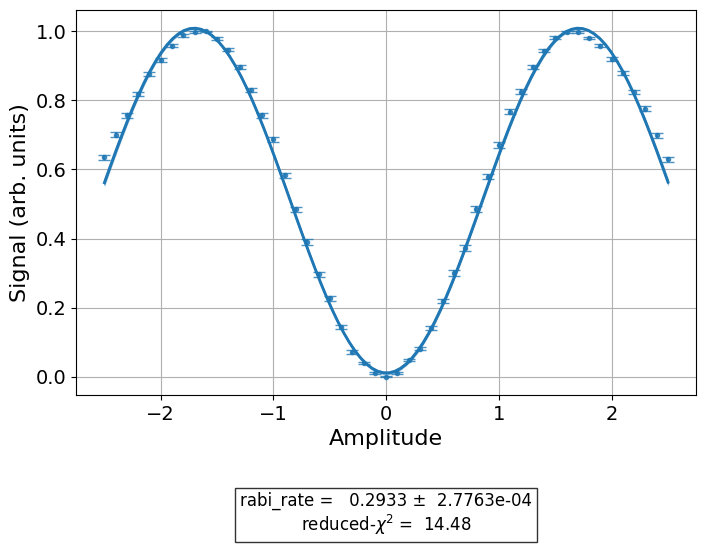

In [41]:
rabi_x1_data.block_for_results()
rabi_x1_data.figure(0)

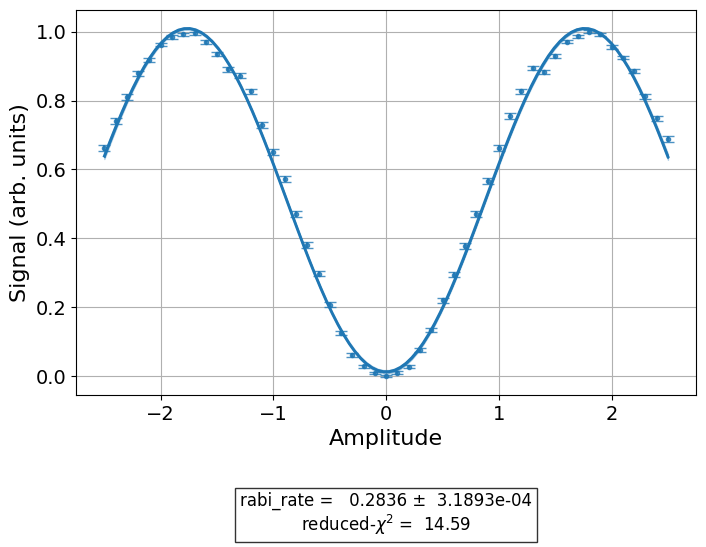

In [42]:
rabi_x2_data.block_for_results()
rabi_x2_data.figure(0)

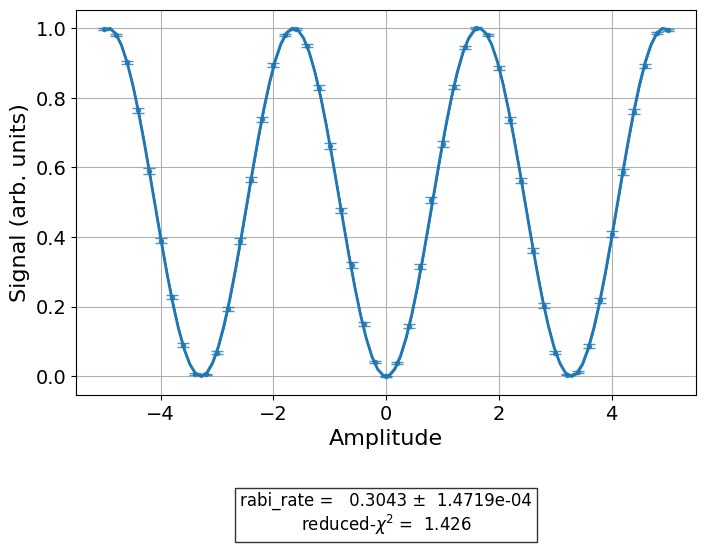

In [43]:
rabi_x1_data_gaussian.block_for_results()
rabi_x1_data_gaussian.figure(0)

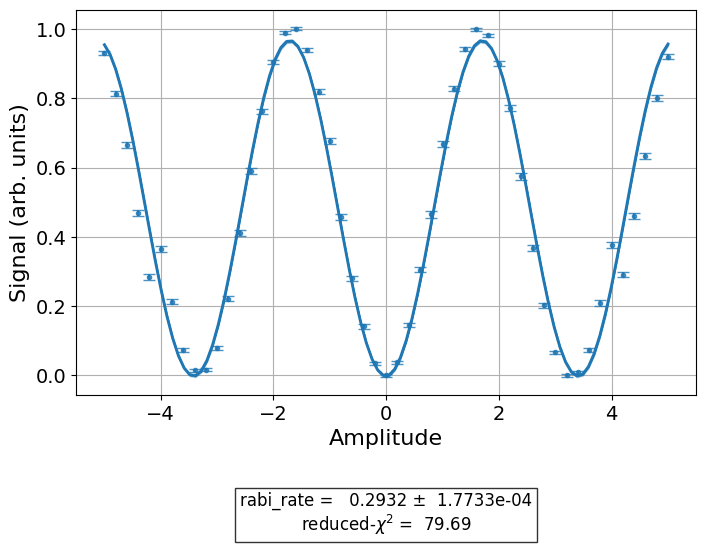

In [44]:
rabi_x2_data_gaussian.block_for_results()
rabi_x2_data_gaussian.figure(0)

In [45]:
from qiskit_experiments.calibration_management.update_library import BaseUpdater

def update_param(exp, exp_data, angle = np.pi):
    result_index = exp.experiment_options.result_index
    rate = 2 * np.pi * BaseUpdater.get_value(exp_data, exp.__outcome__, result_index)

    # angle, _, _, prev_amp = exp_data.metadata["angles_schedules"][0]
    value = np.round(angle / rate, decimals=8)
    print(f"Target angle: {angle}")
    print(f"New amplitude: {value}")
    return value

In [46]:
rough_x1_amp = update_param(rabi_x1, rabi_x1_data)
rough_x2_amp = update_param(rabi_x2, rabi_x2_data)

Target angle: 3.141592653589793
New amplitude: 1.70480558
Target angle: 3.141592653589793
New amplitude: 1.76274217


In [47]:
rough_x1_amp_gaussian = update_param(rabi_x1_gaussian, rabi_x1_data_gaussian)
rough_x2_amp_gaussian = update_param(rabi_x2_gaussian, rabi_x2_data_gaussian)

Target angle: 3.141592653589793
New amplitude: 1.64326948
Target angle: 3.141592653589793
New amplitude: 1.70558318


In [52]:
cals.add_parameter_value(rough_x1_amp, Parameter("amp"), (qubit0,), "x")
cals.add_parameter_value(rough_x2_amp, Parameter("amp"), (qubit1,), "x")

In [53]:
gaussian_cals.add_parameter_value(rough_x1_amp_gaussian, Parameter("amp"), (qubit0,), "x")
gaussian_cals.add_parameter_value(rough_x2_amp_gaussian, Parameter("amp"), (qubit1,), "x")

In [54]:
rough_x1 = cals.get_schedule("x", (qubit0,))
rough_x2 = cals.get_schedule("x", (qubit1,))
rough_x1, rough_x2

(ScheduleBlock(Play(x(duration=120, amp=1.70480558, angle=0), DriveChannel(4)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.76274217, angle=0), DriveChannel(3)), name="x", transform=AlignLeft()))

In [55]:
rough_x1_gaussian = gaussian_cals.get_schedule("x", (qubit0,))
rough_x2_gaussian = gaussian_cals.get_schedule("x", (qubit1,))
rough_x1_gaussian, rough_x2_gaussian

(ScheduleBlock(Play(x(duration=120, amp=1.64326948, angle=0), DriveChannel(4)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.70558318, angle=0), DriveChannel(3)), name="x", transform=AlignLeft()))

In [56]:
np.trapz(rough_x1.instructions[0][1].pulse.get_waveform().samples, dx=dt), np.trapz(rough_x2.instructions[0][1].pulse.get_waveform().samples, dx=dt)

((-5.3488897742152535+0j), (5.53166454190325+0j))

In [57]:
np.trapz(rough_x1_gaussian.instructions[0][1].pulse.get_waveform().samples, dx=dt), np.trapz(rough_x2_gaussian.instructions[0][1].pulse.get_waveform().samples, dx=dt)

((5.162463956915545+0j), (5.358227484558041+0j))

## Fine calibration 

In [58]:
current_x1 = cals.get_schedule("x", (qubit0,))
current_x2 = cals.get_schedule("x", (qubit1,))
current_x1, current_x2

(ScheduleBlock(Play(x(duration=120, amp=1.70480558, angle=0), DriveChannel(4)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.76274217, angle=0), DriveChannel(3)), name="x", transform=AlignLeft()))

In [59]:
current_x1_gaussian = gaussian_cals.get_schedule("x", (qubit0,))
current_x2_gaussian = gaussian_cals.get_schedule("x", (qubit1,))
current_x1_gaussian, current_x2_gaussian

(ScheduleBlock(Play(x(duration=120, amp=1.64326948, angle=0), DriveChannel(4)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.70558318, angle=0), DriveChannel(3)), name="x", transform=AlignLeft()))

In [60]:
def get_fine_circuit(length: int, qubit: int, num_qubits: int, schedule):
    qc = qk.QuantumCircuit(num_qubits, 1)
    qc.sx(qubit)
    for _ in range(length):
        qc.x(qubit)
    qc.measure(qubit, 0)

    x_gate = qk.circuit.library.XGate()
    qc.add_calibration(x_gate, (qubit,), schedule)

    return qc

In [61]:
num_qubits = backend.num_qubits

In [62]:
session = Session(backend=backend)
print(f"Session id: {session.session_id}")
sampler = Sampler(backend=backend, session=session)

Session id: ct46dddkmkz00086d13g


In [63]:
lengths = range(0, 20)

In [64]:
x1_testing = [get_fine_circuit(l, qubit0, num_qubits, current_x1) for l in lengths]
x2_testing = [get_fine_circuit(l, qubit1, num_qubits, current_x2) for l in lengths]

In [65]:
x1_testing_gaussian = [get_fine_circuit(l, qubit0, num_qubits, current_x1_gaussian) for l in lengths]
x2_testing_gaussian = [get_fine_circuit(l, qubit1, num_qubits, current_x2_gaussian) for l in lengths]

In [ ]:
x1_testing_job = sampler.run(x1_testing, shots=1024)
x2_testing_job = sampler.run(x2_testing, shots=1024)

In [80]:
x1_testing_job_gaussian = sampler.run(x1_testing_gaussian, shots=1024)
x2_testing_job_gaussian = sampler.run(x2_testing_gaussian, shots=1024)

In [76]:
x1_testing_job.job_id(), x2_testing_job.job_id()

('ct28fxq81n1g008qjk0g', 'ct28fy7538eg0085h0tg')

In [88]:
x1_testing_job_gaussian.job_id(), x2_testing_job_gaussian.job_id()

('ct46dv78t340008xpmvg', 'ct46dvq2tw9g008kzqf0')

In [84]:
x1_testing_job.status(), x2_testing_job.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [106]:
x1_testing_job_gaussian.status(), x2_testing_job_gaussian.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [108]:
x1_testing_job = service.job("ct28fxq81n1g008qjk0g")
x2_testing_job = service.job("ct28fy7538eg0085h0tg")

In [109]:
x1_testing_job_gaussian = service.job("ct46dv78t340008xpmvg")
x2_testing_job_gaussian = service.job("ct46dvq2tw9g008kzqf0")

In [110]:
x1_results = x1_testing_job.result()
x1_counts = []
for result in x1_results:
    x1_counts.append(result.data.c.get_counts()['1'] / 1024)

x2_results = x2_testing_job.result()
x2_counts = []
for result in x2_results:
    x2_counts.append(result.data.c.get_counts()['1'] / 1024)

In [111]:
x1_results_gaussian = x1_testing_job_gaussian.result()
x1_counts_gaussian = []
for result in x1_results_gaussian:
    x1_counts_gaussian.append(result.data.c.get_counts()['1'] / 1024)

x2_results_gaussian = x2_testing_job_gaussian.result()
x2_counts_gaussian = []
for result in x2_results_gaussian:
    x2_counts_gaussian.append(result.data.c.get_counts()['1'] / 1024)

In [112]:
def get_d_theta(counts, estimate=0.1, plot=True):
    def fit_function(x_values, y_values, function, init_params):
        fitparams, conv = curve_fit(function, x_values, y_values, init_params)
        y_fit = function(x_values, *fitparams)
        return fitparams, y_fit, conv

    starting_params = [estimate]
    fit_params, y_fit, _ = fit_function(
        lengths,
        counts,
        lambda x, d_theta: (
            (1 / 2) * np.cos((d_theta + np.pi) * x - (np.pi / 2)) + 0.5
        ),
        starting_params,
    )

    if plot:
        fine_fit = [(1 / 2) * np.cos((fit_params[0] + np.pi) * x - (np.pi / 2)) + 0.5 for x in np.linspace(0, lengths[-1], 200)]
        plt.scatter(lengths, counts, marker="x", color="black")
        plt.plot(np.linspace(0, lengths[-1], 200), fine_fit)

        plt.xlabel("Maximum pulse amplitude")
        plt.ylabel("Prob. of meas. 1")
        plt.title("Fine amplitude calibration")
        plt.show()

    d_theta = fit_params[0]  # get over/under rotation
    return d_theta

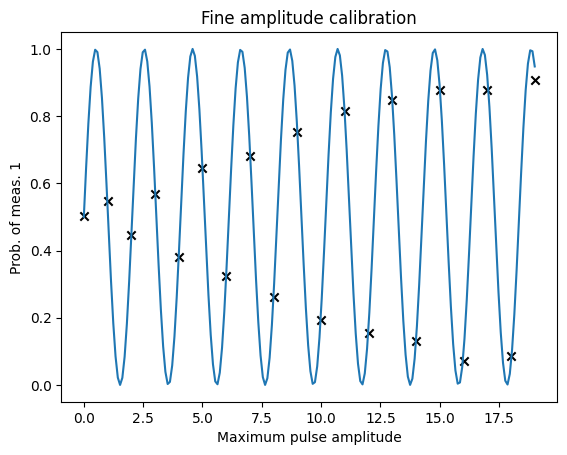

In [113]:
d_theta_x1 = get_d_theta(x1_counts, 0.1)

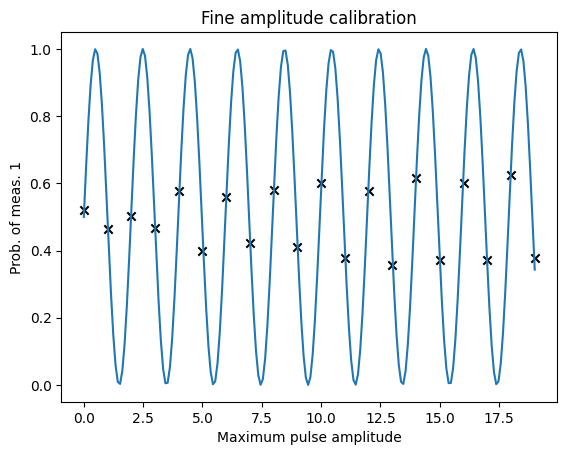

In [114]:
d_theta_x2 = get_d_theta(x2_counts, 0.1)

In [115]:
scale_x1 = (np.pi) / (np.pi + d_theta_x1)
scale_x2 = (np.pi) / (np.pi + d_theta_x2)
scale_x1, scale_x2

(1.0189431150180124, 0.9946848131294614)

In [116]:
fine_x1_amp = rough_x1_amp * scale_x1
fine_x2_amp = rough_x2_amp * scale_x2
fine_x1_amp, fine_x2_amp

(1.7370999081852891, 1.7533728659618715)

In [117]:
cals.add_parameter_value(fine_x1_amp, Parameter("amp"), (qubit0,), "x")
cals.add_parameter_value(fine_x2_amp, Parameter("amp"), (qubit1,), "x")

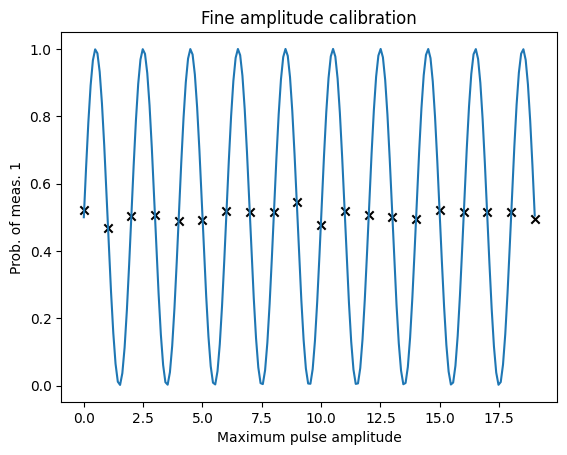

In [118]:
d_theta_x1_gaussian = get_d_theta(x1_counts_gaussian, 0.1)

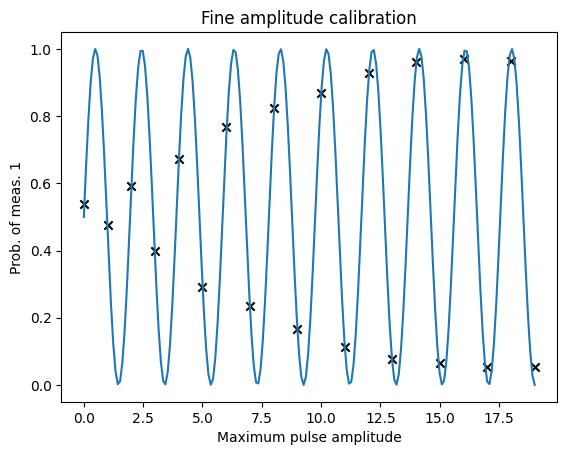

In [119]:
d_theta_x2_gaussian = get_d_theta(x2_counts_gaussian, 0.1)

In [120]:
scale_x1_gaussian = (np.pi) / (np.pi + d_theta_x1_gaussian)
scale_x2_gaussian = (np.pi) / (np.pi + d_theta_x2_gaussian)
scale_x1_gaussian, scale_x2_gaussian

(1.0001565866231492, 0.9747885908004165)

In [121]:
fine_x1_amp_gaussian = rough_x1_amp_gaussian * scale_x1_gaussian
fine_x2_amp_gaussian = rough_x2_amp_gaussian * scale_x2_gaussian
fine_x1_amp_gaussian, fine_x2_amp_gaussian

(1.6435267940187974, 1.6625830245250932)

In [122]:
gaussian_cals.add_parameter_value(fine_x1_amp_gaussian, Parameter("amp"), (qubit0,), "x")
gaussian_cals.add_parameter_value(fine_x2_amp_gaussian, Parameter("amp"), (qubit1,), "x")

## Dynamical decoupling sequences

In [125]:
final_x1 = cals.get_schedule("x", (qubit0,))
final_x2 = cals.get_schedule("x", (qubit1,))
final_x1, final_x2

(ScheduleBlock(Play(x(duration=120, amp=1.7370999082, angle=0), DriveChannel(4)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.753372866, angle=0), DriveChannel(3)), name="x", transform=AlignLeft()))

In [126]:
final_x1_gaussian = gaussian_cals.get_schedule("x", (qubit0,))
final_x2_gaussian = gaussian_cals.get_schedule("x", (qubit1,))
final_x1_gaussian, final_x2_gaussian

(ScheduleBlock(Play(x(duration=120, amp=1.643526794, angle=0), DriveChannel(4)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.6625830245, angle=0), DriveChannel(3)), name="x", transform=AlignLeft()))

In [127]:
def xyxy_sequence(repetitions: int, num_qubits: int, q0: int, q1: int, schedules = None):
    qc = qk.QuantumCircuit(num_qubits, 2)
    qc.sx(q0)
    qc.sx(q1)
    for _ in range(repetitions):
        qc.x(q0)
        qc.rz(np.pi, q0)
        qc.x(q0)
        qc.x(q0)
        qc.rz(np.pi, q0)
        qc.x(q0)

        qc.x(q1)
        qc.rz(np.pi, q1)
        qc.x(q1)
        qc.x(q1)
        qc.rz(np.pi, q1)
        qc.x(q1)
    qc.sx(q0)
    qc.sx(q1)
    qc.measure(q0, 0)
    qc.measure(q1, 1)

    if schedules is not None:
        x_gate = qk.circuit.library.XGate()
        qc.add_calibration(x_gate, (q0,), schedules[0])
        qc.add_calibration(x_gate, (q1,), schedules[1])

    return qc

In [128]:
num_qubits = backend.num_qubits
num_qubits

127

In [129]:
example = xyxy_sequence(1, num_qubits, qubit0, qubit1)
example.draw(idle_wires=False)

┌────┐┌───┐┌───────┐┌───┐┌───┐┌───────┐┌───┐┌────┐   ┌─┐
q_3: ┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ √X ├───┤M├
     ├────┤├───┤├───────┤├───┤├───┤├───────┤├───┤├────┤┌─┐└╥┘
q_4: ┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ √X ├┤M├─╫─
     └────┘└───┘└───────┘└───┘└───┘└───────┘└───┘└────┘└╥┘ ║ 
c: 2/═══════════════════════════════════════════════════╩══╩═
                                                        0  1

In [130]:
lengths = list(range(0, 401, 4))

In [131]:
dd_circuits_robust = [xyxy_sequence(i, num_qubits, qubit0, qubit1, [final_x1, final_x2]) for i in lengths]
dd_circuits_gaussian = [xyxy_sequence(i, num_qubits, qubit0, qubit1, [final_x1_gaussian, final_x2_gaussian]) for i in lengths]
dd_circuits_default = [xyxy_sequence(i, num_qubits, qubit0, qubit1) for i in lengths]

In [798]:
dd_jobs_robust = sampler.run(dd_circuits_robust, shots=2048)
dd_jobs_guassian = sampler.run(dd_circuits_gaussian, shots=2048)
dd_jobs_default = sampler.run(dd_circuits_default, shots=2048)

In [132]:
dd_jobs_gaussian = sampler.run(dd_circuits_gaussian, shots=2048)

In [138]:
dd_jobs_robust.job_id(), dd_jobs_default.job_id(), dd_jobs_gaussian.job_id()

('ct2arpj7srd000888apg', 'ct2arqa2tw9g008kj1jg', 'ct4bp40kmkz00086eq80')

In [142]:
dd_jobs_robust.status(), dd_jobs_default.status(), dd_jobs_gaussian.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [143]:
dd_jobs_robust = service.job("ct2arpj7srd000888apg")
dd_jobs_default = service.job("ct2arqa2tw9g008kj1jg")
dd_jobs_gaussian = service.job("ct4bp40kmkz00086eq80")

In [144]:
robust_results = dd_jobs_robust.result()
robust_counts = []
robust_counts_q0 = []
robust_counts_q1 = []
for result in robust_results:
    robust_counts.append(result.data.c.get_counts())
    robust_counts_q0.append(result.data.c.slice_bits(0).get_counts())
    robust_counts_q1.append(result.data.c.slice_bits(1).get_counts())

default_results = dd_jobs_default.result()
default_counts = []
default_counts_q0 = []
default_counts_q1 = []
for result in default_results:
    default_counts.append(result.data.c.get_counts())
    default_counts_q0.append(result.data.c.slice_bits(0).get_counts())
    default_counts_q1.append(result.data.c.slice_bits(1).get_counts())


gaussian_results = dd_jobs_guassian.result()
gaussian_counts = []
gaussian_counts_q0 = []
gaussian_counts_q1 = []
for result in gaussian_results:
    gaussian_counts.append(result.data.c.get_counts())
    gaussian_counts_q0.append(result.data.c.slice_bits(0).get_counts())
    gaussian_counts_q1.append(result.data.c.slice_bits(1).get_counts())

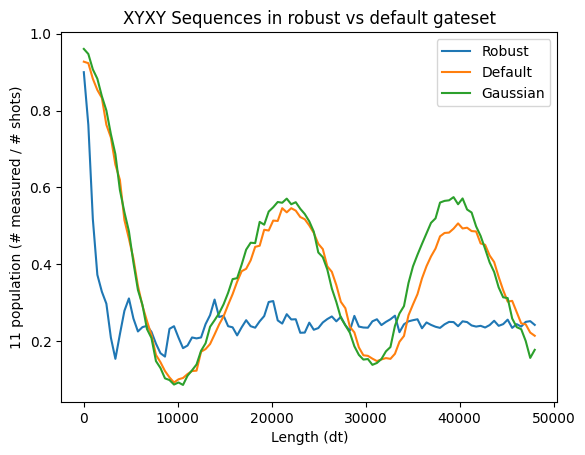

In [146]:
robust_11 = [count.get("11", 0) / 2048 for count in robust_counts]
default_11 = [count.get("11", 0) / 2048 for count in default_counts]
gaussian_11 = [count.get("11", 0) / 2048 for count in gaussian_counts]

plt.plot([l * desired_duration for l in lengths], robust_11, label="Robust")
plt.plot([l * 120 for l in lengths], default_11, label="Default")
plt.plot([l * 120 for l in lengths], gaussian_11, label="Gaussian")
plt.xlabel("Length (dt)")
plt.ylabel("11 population (# measured / # shots)")
plt.title("XYXY Sequences in robust vs default gateset")
plt.legend()
plt.show()

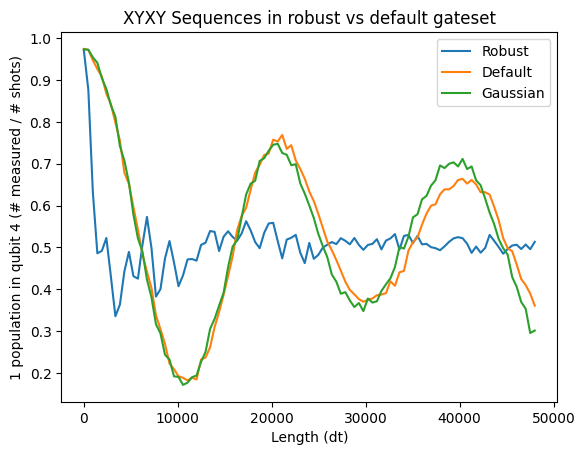

In [147]:
robust_1 = [count.get("1", 0) / 2048 for count in robust_counts_q0]
default_1 = [count.get("1", 0)  / 2048 for count in default_counts_q0]
gaussian_1 = [count.get("1", 0)  / 2048 for count in gaussian_counts_q0]

plt.plot([l * desired_duration for l in lengths], robust_1, label="Robust")
plt.plot([l * 120 for l in lengths], default_1, label="Default")
plt.plot([l * 120 for l in lengths], gaussian_1, label="Gaussian")
plt.xlabel("Length (dt)")
plt.ylabel(f"1 population in qubit {qubit0} (# measured / # shots)")
plt.title("XYXY Sequences in robust vs default gateset")
plt.legend()
plt.show()

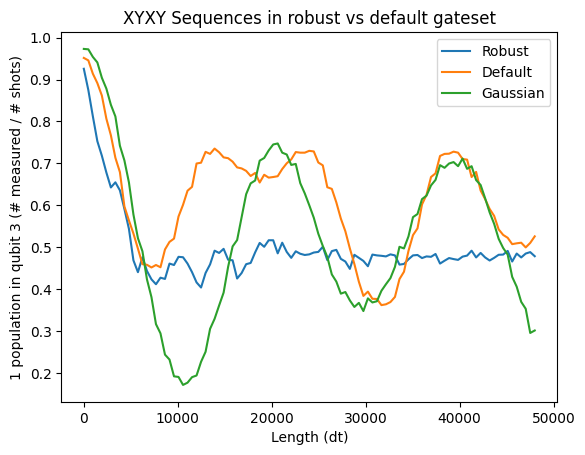

In [148]:
robust_1= [count.get("1", 0) / 2048 for count in robust_counts_q1]
default_1 = [count.get("1", 0)  / 2048 for count in default_counts_q1]

plt.plot([l * desired_duration for l in lengths], robust_1, label="Robust")
plt.plot([l * 120 for l in lengths], default_1, label="Default")
plt.plot([l * 120 for l in lengths], gaussian_1, label="Gaussian")
plt.xlabel("Length (dt)")
plt.ylabel(f"1 population in qubit {qubit1} (# measured / # shots)")
plt.title("XYXY Sequences in robust vs default gateset")
plt.legend()
plt.show()